In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tehran_house_prices_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())
display(df.dtypes)

Dataset shape: (3256, 8)

Columns:
['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address', 'Price', 'Price(USD)']


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


Area            int64
Room            int64
Parking          bool
Warehouse        bool
Elevator         bool
Address           str
Price         float64
Price(USD)    float64
dtype: object

In [2]:
print("Shape:", df.shape)

print("\nMissing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe().T)

print("\nUnique addresses:", df["Address"].nunique())
print("\nAddress examples:")
display(df["Address"].value_counts().head(15))

Shape: (3256, 8)

Missing values:


Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address       0
Price         0
Price(USD)    0
dtype: int64


Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Area,3256.0,1.077804e+02,7.188803e+01,32.00,7.000000e+01,9.000000e+01,1.210000e+02,1.000000e+03
Room,3256.0,2.092445e+00,7.565737e-01,1.00,2.000000e+00,2.000000e+00,2.000000e+00,5.000000e+00
Price,3256.0,5.443781e+09,8.163960e+09,55000000.00,1.440000e+09,2.970000e+09,6.126000e+09,9.240000e+10
Price(USD),3256.0,1.814594e+05,2.721320e+05,1833.33,4.800000e+04,9.900000e+04,2.042000e+05,3.080000e+06



Unique addresses: 193

Address examples:


Address
Punak                        148
West Ferdows Boulevard       133
Gheitarieh                   132
Shahran                      123
Pardis                       123
Saadat Abad                  120
Parand                       118
Shahr-e-Ziba                  91
Jeyhoon                       88
Southern Janatabad            86
Central Janatabad             83
Andisheh                      80
Persian Gulf Martyrs Lake     76
East Ferdows Boulevard        71
Niavaran                      67
Name: count, dtype: int64

In [3]:
TARGET = "Price"

LEAKAGE_COLUMNS = ["Price(USD)"]

print("Target:", TARGET)
print("Leakage columns:", LEAKAGE_COLUMNS)

candidate_features = [
    col for col in df.columns
    if col not in [TARGET] + LEAKAGE_COLUMNS
]

print("\nCandidate input features:")
print(candidate_features)

Target: Price
Leakage columns: ['Price(USD)']

Candidate input features:
['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address']


In [4]:
eda_df = df.copy()

eda_df["Price_per_sqm"] = (
    eda_df["Price"] / eda_df["Area"]
)

display(
    eda_df[
        ["Area", "Price", "Price_per_sqm", "Address"]
    ].head(10)
)

print("\nPrice per square meter summary:")
display(eda_df["Price_per_sqm"].describe())

,Area,Price,Price_per_sqm,Address
0,63,1.850000e+09,2.936508e+07,Shahran
1,60,1.850000e+09,3.083333e+07,Shahran
2,79,5.500000e+08,6.962025e+06,Pardis
3,95,9.025000e+08,9.500000e+06,Shahrake Qods
4,123,7.000000e+09,5.691057e+07,Shahrake Gharb
5,70,2.050000e+09,2.928571e+07,North Program Organization
6,87,6.000000e+08,6.896552e+06,Pardis
7,59,2.150000e+09,3.644068e+07,Shahran
8,54,4.930000e+08,9.129630e+06,Andisheh
9,71,2.370000e+09,3.338028e+07,West Ferdows Boulevard



Price per square meter summary:


count    3.256000e+03
mean     4.163248e+07
std      3.184653e+07
min      6.626506e+05
25%      2.000000e+07
50%      3.500000e+07
75%      5.500000e+07
max      4.166667e+08
Name: Price_per_sqm, dtype: float64

In [5]:
amenity_cols = ["Parking", "Warehouse", "Elevator"]

for col in amenity_cols:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print(df[col].value_counts(dropna=False))


Parking
Data type: bool
Parking
True     2760
False     496
Name: count, dtype: int64

Warehouse
Data type: bool
Warehouse
True     2980
False     276
Name: count, dtype: int64

Elevator
Data type: bool
Elevator
True     2563
False     693
Name: count, dtype: int64


In [6]:
display(
    df.groupby("Address")[amenity_cols]
    .mean(numeric_only=True)
    .head(10)
)

,Parking,Warehouse,Elevator
Address,,,
Abazar,1.000000,1.000000,0.956522
Abbasabad,1.000000,1.000000,1.000000
Absard,0.833333,0.833333,0.000000
Abuzar,0.333333,0.333333,0.333333
Afsarieh,0.666667,0.666667,0.500000
Ahang,0.500000,0.500000,0.500000
Air force,0.800000,0.600000,0.700000
Ajudaniye,1.000000,1.000000,1.000000
Alborz Complex,1.000000,1.000000,0.000000


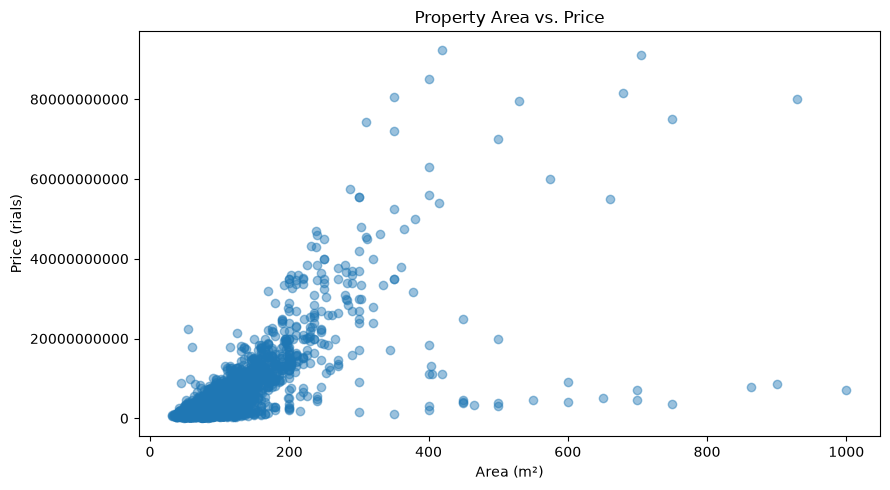

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.scatter(df["Area"], df["Price"], alpha=0.45)
plt.xlabel("Area (m²)")
plt.ylabel("Price (rials)")
plt.title("Property Area vs. Price")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [8]:
neighborhood_stats = (
    df.groupby("Address")["Price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(neighborhood_stats.head(15))
display(neighborhood_stats.tail(15))

,count,median,mean
Address,,,
Gandhi,1,7.000000e+10,7.000000e+10
Lavasan,4,4.100000e+10,4.800000e+10
Vanak,2,3.270000e+10,3.270000e+10
Elahieh,17,3.166800e+10,2.678635e+10
Argentina,2,2.516500e+10,2.516500e+10
Farmanieh,56,2.000000e+10,2.066580e+10
Zaferanieh,27,1.800000e+10,2.357515e+10
Mahmoudieh,3,1.700000e+10,3.346667e+10
Niavaran,67,1.680000e+10,1.986027e+10


,count,median,mean
Address,,,
Pardis,123,670000000.0,7.937154e+08
Khavaran,3,668000000.0,6.756667e+08
Shahrake Quds,5,650000000.0,9.070000e+08
Alborz Complex,1,645000000.0,6.450000e+08
Naziabad,1,640000000.0,6.400000e+08
Ghiyamdasht,1,640000000.0,6.400000e+08
Baghestan,8,610000000.0,7.068750e+08
Vahidiyeh,2,554000000.0,5.540000e+08
Hassan Abad,1,510000000.0,5.100000e+08


In [9]:
TARGET = "Price"

FEATURES = [
    "Area",
    "Room",
    "Parking",
    "Warehouse",
    "Elevator",
    "Address",
]

X = df[FEATURES].copy()
y = df[TARGET].copy()

assert "Price" not in X.columns
assert "Price(USD)" not in X.columns
assert len(X) == len(y)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("\nFeature data types:")
display(X.dtypes)

Feature matrix: (3256, 6)
Target vector: (3256,)

Feature data types:


Area         int64
Room         int64
Parking       bool
Warehouse     bool
Elevator      bool
Address        str
dtype: object

In [ ]:

TARGET = "Price"

NUMERIC_FEATURES = ["Area", "Room"]
BOOLEAN_FEATURES = ["Parking", "Warehouse", "Elevator"]
CATEGORICAL_FEATURES = ["Address"]

FEATURES = (
    NUMERIC_FEATURES
    + BOOLEAN_FEATURES
    + CATEGORICAL_FEATURES
)

X = df[FEATURES].copy()
y = df[TARGET].copy()


eda_df = df.copy()
eda_df["Price_per_sqm"] = eda_df["Price"] / eda_df["Area"]

assert TARGET not in X.columns
assert "Price(USD)" not in X.columns
assert "Price_per_sqm" not in X.columns
assert len(X) == len(y)
assert X.isna().sum().sum() == 0
assert y.notna().all()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature groups:")
print("Numeric:", NUMERIC_FEATURES)
print("Boolean:", BOOLEAN_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)

display(X.head())

In [ ]:
from pathlib import Path

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

X.to_csv(
    output_dir / "model_features.csv",
    index=False
)

y.to_frame().to_csv(
    output_dir / "model_target.csv",
    index=False
)

print("Saved:")
print(output_dir / "model_features.csv")
print(output_dir / "model_target.csv")

In [ ]:
import matplotlib.pyplot as plt

price_sqm_by_area = (
    eda_df.groupby("Address")
    .agg(
        property_count=("Price", "size"),
        median_price_per_sqm=("Price_per_sqm", "median"),
    )
    .query("property_count >= 10")
    .sort_values("median_price_per_sqm", ascending=False)
)

top_neighborhoods = price_sqm_by_area.head(15).sort_values(
    "median_price_per_sqm"
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_neighborhoods.index,
    top_neighborhoods["median_price_per_sqm"]
)

ax.set_xlabel("Median price per square meter (rials)")
ax.set_ylabel("Neighborhood")
ax.set_title("Neighborhood Comparison: Median Price per m²")
ax.ticklabel_format(style="plain", axis="x")

fig.tight_layout()

fig.savefig(
    PROJECT_ROOT / "figures" / "neighborhood_price_per_sqm.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

assert X.shape == (3256, 6)
assert len(y) == 3256
assert "Price" not in X.columns
assert "Price(USD)" not in X.columns
assert "Price_per_sqm" not in X.columns

print("All Day 3 feature checks passed.")